### PREDICTING AMOUNT OF FARE BY DISTANCE, TIME AND DAY OF THE WEEK FOR NYC YELLOW TAXIS. (USING SEP 2026 DATASET ON STANDARD RATE)

In [27]:
import pandas as pd
import numpy as np

Loading the data and EDA

In [3]:
df = pd.read_parquet("data/yellow_tripdata_2026-09.parquet")
print(df.shape)
df.head()

(3876044, 21)


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,request_source
0,2,2026-09-01 00:06:31,2026-09-01 00:25:27,1.0,7.06,1.0,N,70,41,1,...,6.00,0.5,4.03,7.46,1.0,51.99,0.0,2.0,0.00,NaN
1,2,2026-09-01 00:45:04,2026-09-01 00:51:27,1.0,1.16,1.0,N,229,163,1,...,1.00,0.5,2.73,0.00,1.0,16.38,2.5,0.0,0.75,NaN
2,1,2026-09-01 00:10:55,2026-09-01 00:20:36,1.0,2.50,1.0,N,236,162,1,...,4.25,0.5,3.85,0.00,1.0,23.10,2.5,0.0,0.75,NaN
3,1,2026-09-01 00:21:49,2026-09-01 00:28:23,1.0,1.60,1.0,N,162,141,1,...,4.25,0.5,3.00,0.00,1.0,18.05,2.5,0.0,0.75,NaN
4,2,2026-09-01 00:06:07,2026-09-01 00:11:41,4.0,1.31,1.0,N,137,79,1,...,1.00,0.5,6.35,0.00,1.0,20.00,2.5,0.0,0.75,NaN


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3876044 entries, 0 to 3876043
Data columns (total 21 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     str           
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee            float64   

In [5]:
print(df.isna().sum())

VendorID                       0
tpep_pickup_datetime           0
tpep_dropoff_datetime          0
passenger_count          1190413
trip_distance                  0
RatecodeID               1190413
store_and_fwd_flag       1190413
PULocationID                   0
DOLocationID                   0
payment_type                   0
fare_amount                    0
extra                          0
mta_tax                        0
tip_amount                     0
tolls_amount                   0
improvement_surcharge          0
total_amount                   0
congestion_surcharge     1190413
Airport_fee              1190413
cbd_congestion_fee             0
request_source           2685952
dtype: int64


In [6]:
# Looking at the summary of below data, we can conclude that there are many missing values in the dataset like passenger_count
# fare_amount has negative values also which is junk as negative fare_amount is not possible. We will remove those rows from the dataset.
# The 25%, 50% and 75% rows look sensible (median trip about 2 miles, about $17.70). So most of the data is fine, and the junk sits at the extremes.
df[["fare_amount", "trip_distance", "passenger_count"]].describe()

,fare_amount,trip_distance,passenger_count
count,3.876044e+06,3.876044e+06,2.685631e+06
mean,2.309796e+01,4.969444e+00,1.224202e+00
std,2.019785e+01,4.634327e+02,6.051486e-01
min,-1.800000e+03,0.000000e+00,0.000000e+00
25%,1.070000e+01,1.060000e+00,1.000000e+00
50%,1.770000e+01,1.960000e+00,1.000000e+00
75%,2.920000e+01,4.150000e+00,1.000000e+00
max,9.999700e+03,2.326448e+05,8.000000e+00


In [ ]:
# RatecodeID 1 is the most common rate code, which is standard rate. RatecodeID 2 is for JFK, 3 is for Newark, 
# 4 is for Nassau or Westchester, 5 is for negotiated fare, and 6 is for group ride. The other rate codes are not used in this dataset.
df['RatecodeID'].value_counts()

RatecodeID
1.0     2448599
99.0      96707
2.0       91759
5.0       30962
3.0        9897
4.0        7707
Name: count, dtype: int64

In [7]:
print('Negative or zero fare_amount found:', (df['fare_amount'] < 0).sum())
print("distance is zero:", (df["trip_distance"] == 0).sum())
print('unusually large distance:', (df['trip_distance'] > 250).sum())
print('unusually high fare_amount:', (df['fare_amount'] > 1000).sum())


Negative or zero fare_amount found: 14190
distance is zero: 147158
unusually large distance: 50
unusually high fare_amount: 4


Data Cleansing 

In [42]:
df_clean = df[
    (df["fare_amount"] > 0) & (df["fare_amount"] <= 1000)
    & (df["trip_distance"] > 0) & (df["trip_distance"] <= 250)
    & (df['RatecodeID'] == 1)
].copy()

df_clean["pickup_hour"] = df_clean["tpep_pickup_datetime"].dt.hour
df_clean["pickup_dayofweek"] = df_clean["tpep_pickup_datetime"].dt.day_of_week
df_clean[["tpep_pickup_datetime", "pickup_hour", "pickup_dayofweek"]].head()

print("before:", len(df), "after:", len(df_clean))

before: 3876044 after: 2417214


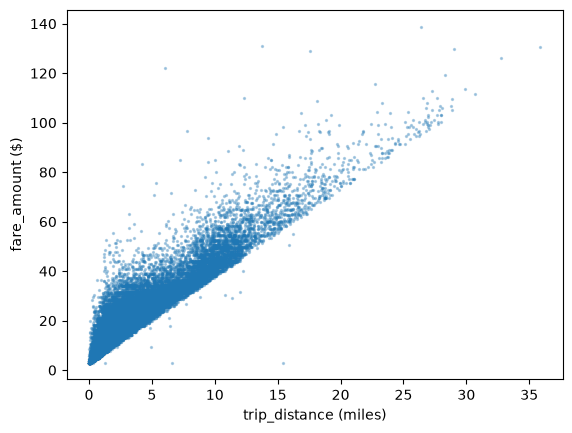

In [43]:
import matplotlib.pyplot as plt
sample = df_clean.sample(50_000, random_state=42)

plt.scatter(sample["trip_distance"], sample["fare_amount"], s=2, alpha=0.3)
plt.xlabel("trip_distance (miles)")
plt.ylabel("fare_amount ($)")
plt.show()

In [44]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

X = df_clean[["trip_distance", "pickup_hour", "pickup_dayofweek"]].copy()
Y = df_clean["fare_amount"].copy()

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["pickup_hour", "pickup_dayofweek"])
    ],
    remainder="passthrough",
)

In [45]:
X_pre_train = preprocessor.fit_transform(X_train)
X_pre_test = preprocessor.transform(X_test)
print(preprocessor.get_feature_names_out())

['cat__pickup_hour_0' 'cat__pickup_hour_1' 'cat__pickup_hour_2'
 'cat__pickup_hour_3' 'cat__pickup_hour_4' 'cat__pickup_hour_5'
 'cat__pickup_hour_6' 'cat__pickup_hour_7' 'cat__pickup_hour_8'
 'cat__pickup_hour_9' 'cat__pickup_hour_10' 'cat__pickup_hour_11'
 'cat__pickup_hour_12' 'cat__pickup_hour_13' 'cat__pickup_hour_14'
 'cat__pickup_hour_15' 'cat__pickup_hour_16' 'cat__pickup_hour_17'
 'cat__pickup_hour_18' 'cat__pickup_hour_19' 'cat__pickup_hour_20'
 'cat__pickup_hour_21' 'cat__pickup_hour_22' 'cat__pickup_hour_23'
 'cat__pickup_dayofweek_0' 'cat__pickup_dayofweek_1'
 'cat__pickup_dayofweek_2' 'cat__pickup_dayofweek_3'
 'cat__pickup_dayofweek_4' 'cat__pickup_dayofweek_5'
 'cat__pickup_dayofweek_6' 'remainder__trip_distance']


In [46]:
from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()
lr_model.fit(X_pre_train, Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](32,)","[-1.28,-1.37,-1.39,...,-0.51,-1.36, 3.98]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,5.955
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,32


In [49]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

pred = lr_model.predict(X_pre_test)

mae = mean_absolute_error(Y_test, pred)
rmse = np.sqrt(mean_squared_error(Y_test, pred))
r2 = r2_score(Y_test, pred)
print(f"MAE: {mae:.2f}  RMSE: {rmse:.2f}  R2: {r2:.3f}")

# reference point: always predicting the average train fare
print("MAE of predicting the mean:", mean_absolute_error(Y_test, np.full(len(Y_test), Y_train.mean())))
print("intercept:", lr_model.intercept_)
print("distance coefficient:", lr_model.coef_[-1])

MAE: 2.93  RMSE: 4.23  R2: 0.896
MAE of predicting the mean: 9.105362701664975
intercept: 5.955053172857932
distance coefficient: 3.977646006525075


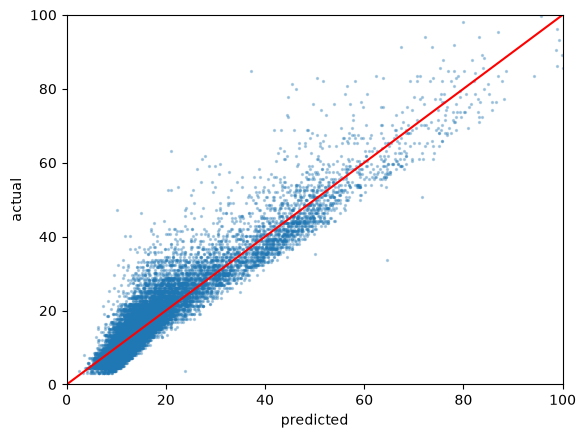

In [53]:
res = pd.DataFrame()
res["actual"] = Y_test
res["pred"] = pred

# predicted vs actual (the red line is a perfect prediction)
s = res.sample(20_000, random_state=42)
plt.scatter(s["pred"], s["actual"], s=2, alpha=0.3)
plt.plot([0, 100], [0, 100], color="red")
plt.xlim(0, 100); plt.ylim(0, 100)
plt.xlabel("predicted"); plt.ylabel("actual")
plt.show()